<a href="https://colab.research.google.com/github/PremKumbhare/Decline-Curve-Analysis/blob/main/Pressure_Loss_Analysis_in_Drilling_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DRILLING HYDRAULICS: PRESSURE LOSS ANALYSIS

Plastic Viscosity (PV) : 12.00 cP
Yield Point (YP)       : 12.00 lb/100ft2
Flow Behaviour Index n : 0.5846
Consistency Index K    : 0.6263 lb.s^n/100ft2

----------------------------------------------------------------------
                Section  Bingham (psi)  Power Law (psi) Regime (BP) Regime (PL)
      Surface Equipment           52.1             52.1           -           -
       Inside Drillpipe          669.9            577.6   Turbulent   Turbulent
   Inside Drill Collars          430.9            321.9   Turbulent   Turbulent
   Annulus: DP / Casing           21.4              5.6     Laminar   Turbulent
Annulus: DP / Open Hole           34.6             10.0     Laminar   Turbulent
Annulus: DC / Open Hole           10.1              5.4     Laminar   Turbulent
      TOTAL SYSTEM LOSS         1219.0            972.6           -           -
        PRESSURE AT BIT          981.0           1227.4           -           -
----------

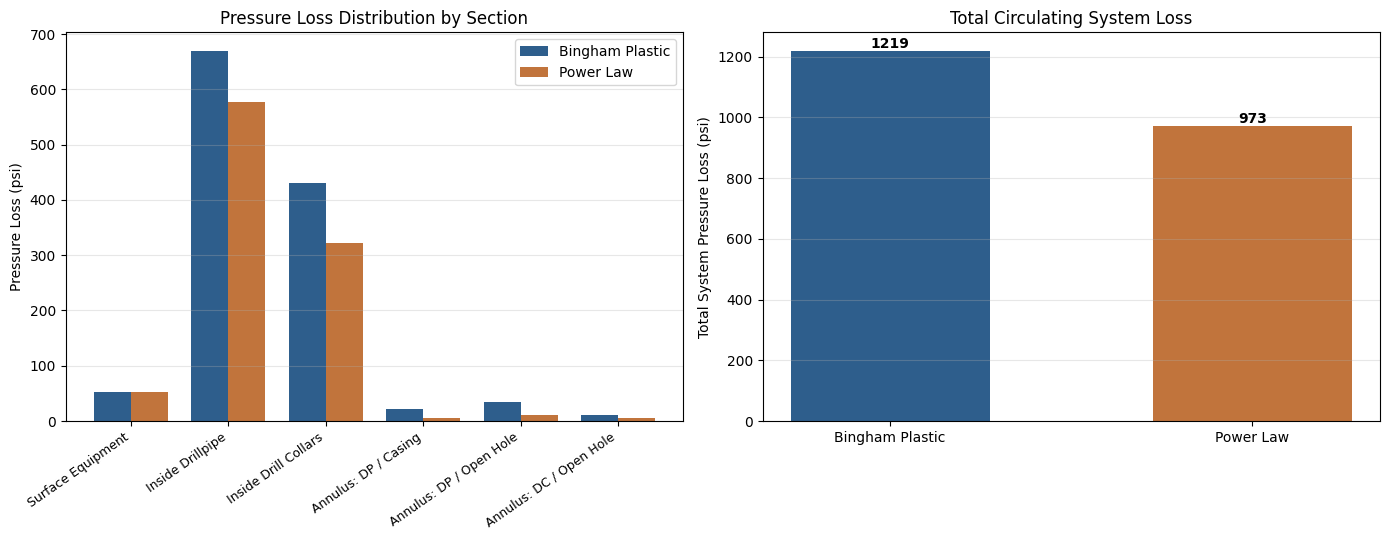

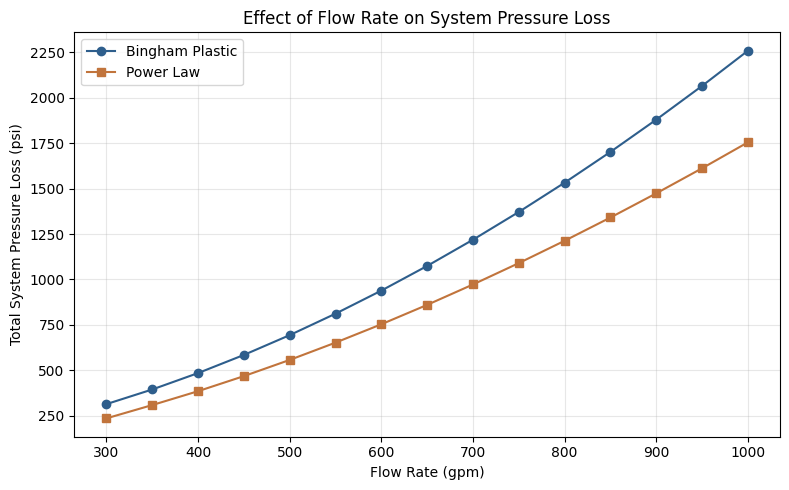


Sensitivity Analysis:
 Flow Rate (gpm)  Bingham (psi)  Power Law (psi)
             300          314.3            235.9
             350          394.9            309.1
             400          485.1            385.4
             450          584.9            468.3
             500          693.9            557.5
             550          812.0            652.7
             600          939.0            753.7
             650         1074.7            860.4
             700         1219.0            972.6
             750         1371.7           1090.2
             800         1532.8           1213.1
             850         1702.2           1341.1
             900         1879.7           1474.1
             950         2065.3           1612.1
            1000         2258.9           1754.9


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

E_SURFACE = {1: 2.5e-4, 2: 9.6e-5, 3: 5.3e-5, 4: 4.2e-5}

WELL = {
    "Q": 700.0,
    "rho": 8.824,
    "theta600": 36.0,
    "theta300": 24.0,
    "surface_type": 4,
    "dp_id": 4.276,
    "dp_od": 5.0,
    "dp_len": 6480.0,
    "dc_id": 2.875,
    "dc_od": 8.0,
    "dc_len": 620.0,
    "casing_id": 12.565,
    "casing_depth": 2550.0,
    "hole_dia": 12.25,
    "pump_pressure": 2200.0,
    "Cd": 0.95,
}


def rheology(theta600, theta300):
    pv = theta600 - theta300
    yp = theta300 - pv
    n = 3.32 * np.log10(theta600 / theta300)
    k = theta300 / 511.0 ** n
    return pv, yp, n, k


def velocity(Q, d_out, d_in=0.0):
    return 24.51 * Q / (d_out ** 2 - d_in ** 2)


def surface_loss(rho, Q, pv, surface_type):
    return E_SURFACE[surface_type] * rho ** 0.8 * Q ** 1.8 * pv ** 0.2


def bingham_critical_velocity(pv, yp, rho, d):
    return (97.0 * pv + 97.0 * np.sqrt(pv ** 2 + 8.2 * rho * d ** 2 * yp)) / (rho * d)


def bingham_loss(rho, Q, pv, yp, L, d_out, d_in=0.0, annulus=False):
    d = d_out - d_in if annulus else d_out
    v = velocity(Q, d_out, d_in)
    vc = bingham_critical_velocity(pv, yp, rho, d)
    if v < vc:
        regime = "Laminar"
        if annulus:
            dp = L * pv * v / (60000.0 * d ** 2) + L * yp / (200.0 * d)
        else:
            dp = L * pv * v / (90000.0 * d ** 2) + L * yp / (225.0 * d)
    else:
        regime = "Turbulent"
        dp = 8.91e-5 * rho ** 0.8 * Q ** 1.8 * pv ** 0.2 * L / d ** 4.8
    return dp, v, vc, regime


def effective_viscosity(n, k, v, d, annulus=False):
    vs = v / 60.0
    if annulus:
        shear = 144.0 * vs / d
        shape = (2.0 * n + 1.0) / (3.0 * n)
    else:
        shear = 96.0 * vs / d
        shape = (3.0 * n + 1.0) / (4.0 * n)
    return 100.0 * k * shear ** (n - 1.0) * shape ** n


def power_law_loss(rho, Q, n, k, L, d_out, d_in=0.0, annulus=False):
    d = d_out - d_in if annulus else d_out
    v = velocity(Q, d_out, d_in)
    vs = v / 60.0
    mu = effective_viscosity(n, k, v, d, annulus)
    re = (757.0 if annulus else 928.0) * rho * vs * d / mu
    re_c = 3470.0 - 1370.0 * n
    if re < re_c:
        regime = "Laminar"
        shape = (2.0 * n + 1.0) / (0.0208 * n) if annulus else (3.0 * n + 1.0) / (0.0416 * n)
        dp = k * v ** n * L * shape ** n / (144000.0 * d ** (1.0 + n))
    else:
        regime = "Turbulent"
        f = 0.0791 / re ** 0.25
        dp = f * rho * vs ** 2 * L / ((21.1 if annulus else 25.81) * d)
    return dp, v, re, regime


def nozzle_sizing(dp_bit, rho, Q, Cd):
    if dp_bit <= 0:
        return float("nan"), float("nan")
    area = Q * np.sqrt(rho / (12031.0 * dp_bit)) / (3.0 * Cd)
    d32 = np.sqrt(4.0 * area / (3.0 * np.pi)) * 32.0
    return area, d32


def analyse(well):
    pv, yp, n, k = rheology(well["theta600"], well["theta300"])
    rho, Q = well["rho"], well["Q"]
    dp_open_len = well["dp_len"] - well["casing_depth"]

    sections = [
        ("Inside Drillpipe", well["dp_len"], well["dp_id"], 0.0, False),
        ("Inside Drill Collars", well["dc_len"], well["dc_id"], 0.0, False),
        ("Annulus: DP / Casing", well["casing_depth"], well["casing_id"], well["dp_od"], True),
        ("Annulus: DP / Open Hole", dp_open_len, well["hole_dia"], well["dp_od"], True),
        ("Annulus: DC / Open Hole", well["dc_len"], well["hole_dia"], well["dc_od"], True),
    ]

    rows = []
    ps = surface_loss(rho, Q, pv, well["surface_type"])
    rows.append(["Surface Equipment", ps, ps, "-", "-"])

    for name, L, d_out, d_in, ann in sections:
        b_dp, v, _, b_reg = bingham_loss(rho, Q, pv, yp, L, d_out, d_in, ann)
        p_dp, _, _, p_reg = power_law_loss(rho, Q, n, k, L, d_out, d_in, ann)
        rows.append([name, b_dp, p_dp, b_reg, p_reg])

    df = pd.DataFrame(rows, columns=["Section", "Bingham (psi)", "Power Law (psi)",
                                     "Regime (BP)", "Regime (PL)"])
    df.loc[len(df)] = ["TOTAL SYSTEM LOSS", df["Bingham (psi)"].sum(),
                       df["Power Law (psi)"].sum(), "-", "-"]

    bit_b = well["pump_pressure"] - df.iloc[-1]["Bingham (psi)"]
    bit_p = well["pump_pressure"] - df.iloc[-1]["Power Law (psi)"]
    df.loc[len(df)] = ["PRESSURE AT BIT", bit_b, bit_p, "-", "-"]

    params = {"PV": pv, "YP": yp, "n": n, "K": k}
    nozzles = {
        "Bingham": nozzle_sizing(bit_b, rho, Q, well["Cd"]),
        "Power Law": nozzle_sizing(bit_p, rho, Q, well["Cd"]),
    }
    return df, params, nozzles


def plot_results(df):
    data = df[~df["Section"].isin(["TOTAL SYSTEM LOSS", "PRESSURE AT BIT"])]
    x = np.arange(len(data))
    w = 0.38

    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

    ax[0].bar(x - w / 2, data["Bingham (psi)"], w, label="Bingham Plastic", color="#2E5E8C")
    ax[0].bar(x + w / 2, data["Power Law (psi)"], w, label="Power Law", color="#C1743C")
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(data["Section"], rotation=35, ha="right", fontsize=9)
    ax[0].set_ylabel("Pressure Loss (psi)")
    ax[0].set_title("Pressure Loss Distribution by Section")
    ax[0].legend()
    ax[0].grid(axis="y", alpha=0.3)

    totals = df[df["Section"] == "TOTAL SYSTEM LOSS"].iloc[0]
    bars = ax[1].bar(["Bingham Plastic", "Power Law"],
                     [totals["Bingham (psi)"], totals["Power Law (psi)"]],
                     color=["#2E5E8C", "#C1743C"], width=0.55)
    ax[1].set_ylabel("Total System Pressure Loss (psi)")
    ax[1].set_title("Total Circulating System Loss")
    ax[1].grid(axis="y", alpha=0.3)
    for bar in bars:
        ax[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                   f"{bar.get_height():.0f}", ha="center", fontweight="bold")

    plt.tight_layout()
    plt.savefig("pressure_loss_analysis.png", dpi=150)
    plt.show()


def sensitivity(well, q_range=np.arange(300, 1001, 50)):
    bing, powl = [], []
    for q in q_range:
        w = dict(well, Q=float(q))
        df, _, _ = analyse(w)
        total = df[df["Section"] == "TOTAL SYSTEM LOSS"].iloc[0]
        bing.append(total["Bingham (psi)"])
        powl.append(total["Power Law (psi)"])

    plt.figure(figsize=(8, 5))
    plt.plot(q_range, bing, "o-", label="Bingham Plastic", color="#2E5E8C")
    plt.plot(q_range, powl, "s-", label="Power Law", color="#C1743C")
    plt.xlabel("Flow Rate (gpm)")
    plt.ylabel("Total System Pressure Loss (psi)")
    plt.title("Effect of Flow Rate on System Pressure Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("sensitivity_flowrate.png", dpi=150)
    plt.show()
    return pd.DataFrame({"Flow Rate (gpm)": q_range, "Bingham (psi)": bing,
                         "Power Law (psi)": powl})


if __name__ == "__main__":
    df, params, nozzles = analyse(WELL)

    print("=" * 70)
    print("DRILLING HYDRAULICS: PRESSURE LOSS ANALYSIS")
    print("=" * 70)
    print(f"\nPlastic Viscosity (PV) : {params['PV']:.2f} cP")
    print(f"Yield Point (YP)       : {params['YP']:.2f} lb/100ft2")
    print(f"Flow Behaviour Index n : {params['n']:.4f}")
    print(f"Consistency Index K    : {params['K']:.4f} lb.s^n/100ft2")

    print("\n" + "-" * 70)
    print(df.to_string(index=False, float_format=lambda v: f"{v:10.1f}"))
    print("-" * 70)

    for model, (area, d32) in nozzles.items():
        print(f"\n{model}: Total nozzle area = {area:.4f} in2 | "
              f"Nozzle size = {d32:.1f}/32 in (x3)")

    plot_results(df)
    sens = sensitivity(WELL)
    print("\nSensitivity Analysis:")
    print(sens.to_string(index=False, float_format=lambda v: f"{v:10.1f}"))